# REGRESIÓN

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, SGDRegressor, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import learning_curve
from sklearn.metrics import mean_squared_error, root_mean_squared_error
from sklearn.svm import LinearSVR
from sklearn.tree import DecisionTreeRegressor, export_graphviz
from graphviz import Source

## EJEMPLO 1: REGRESIÓN LINEAL

Vamos a generar unos datos de aspecto lineal (y=4 + 3x) con un poco de ruido

In [2]:
np.random.seed(42)
m = 100  
X = 2 * np.random.rand(m, 1)  
y = 4 + 3 * X + np.random.randn(m, 1)

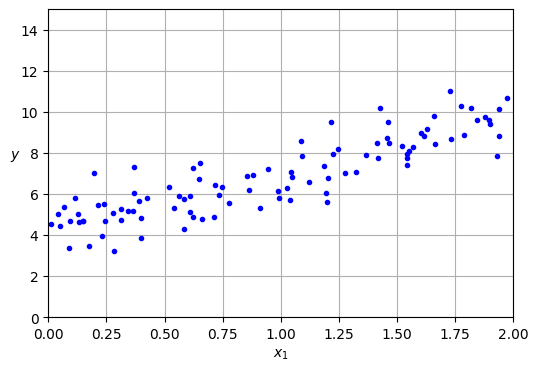

In [3]:
plt.figure(figsize=(6, 4))
plt.plot(X, y, "b.")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([0, 2, 0, 15])
plt.grid()
plt.show()

### LinearRegression
En resumen, este código entrena un modelo de regresión lineal con los datos proporcionados y luego obtiene los parámetros del modelo ajustado. El intercepto [`lin_reg.intercept_`] es el valor de `y` cuando todas las características son 0, y los coeficientes [`lin_reg.coef_`] representan las pendientes de la línea de regresión para cada característica en `X`.

Los coeficientes indican la relación entre cada caracteristica en X y la variable objetivo `y`. Un coeficiente positivo indica una relación directa, mietnras uno negativo indica relación inversa. 



In [4]:
lin_reg = LinearRegression()
lin_reg.fit(X, y) 
lin_reg.intercept_, lin_reg.coef_

(array([4.21509616]), array([[2.77011339]]))

En vez de 4 y 3 (y=4+3x) debibo al error hemos obtenido 4.215 y 2.770 que se acerca bastante.

Vamos a hacer alguna predicción

In [5]:
X_new = np.array([[0], [2]])
y_predict=lin_reg.predict(X_new)
y_predict

array([[4.21509616],
       [9.75532293]])

Por lo tanto, las predicciones [`array([[4.21509616], [9.75532293]])`]indican que, según el modelo ajustado, cuando `X` es [`0`], `y` es aproximadamente `4.215`, y cuando `X` es [`2`], `y` es aproximadamente `9.755`.
Esto muestra que el modelo ha capturado la relación lineal entre `X` y `y` bastante bien, a pesar del ruido en los datos.

Veamos el resultado gráficamente:

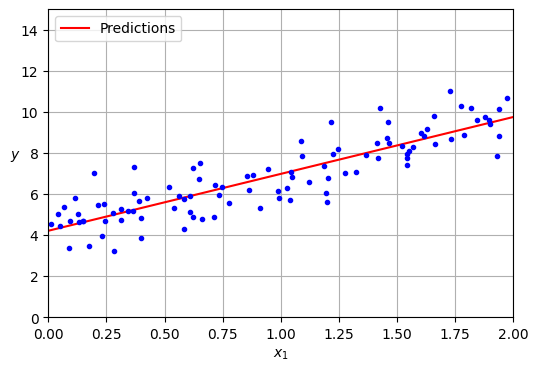

In [6]:
plt.figure(figsize=(6, 4))
plt.plot(X_new, y_predict, "r", label="Predictions")
plt.plot(X, y, "b.")

plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([0, 2, 0, 15])
plt.grid()
plt.legend(loc="upper left")

plt.show()

Aunque hemos visto el resultado gráficamente vamos a calcular el error en el conjunto de entrenamiento (RSME).

In [7]:
y_pred = lin_reg.predict(X) #Utiliza el modelo de regresión lineal entrenado (lin_reg) para predecir los valores de y

mse=mean_squared_error(y, y_pred) 
rmse=root_mean_squared_error(y, y_pred)

y_min=np.min(y)
y_max=np.max(y)
print("Y min:",y_min) # valor min de la variable objetivo 'y' en el conjunto de datos. Esto da una idea del rango inferior de los valores reales
print("Y max:",y_max) # valor max de la variable objetivo 'y' en el conjunto de datos. Esto da una idea del rango superior de los valores reales
print("MSE:",mse) # Medida de precisión, un valor mas bajo indica un mejor ajuste del modelo a los datos
print("RMSE:", rmse) # Medida de precisión, un valor mas bajo indica un mejor ajuste del modelo a los datos

Y min: 3.2380621152873488
Y max: 11.044395066398318
MSE: 0.8065845639670531
RMSE: 0.8981005311027564


#### Interpretación de resultados de Linear Regression:
* `Comparación con el rango de y`:
    * El RMSE de 0.90 es relativamente pequeño en comparación con el rango de y (3.24 a 11.04). Esto sugiere que el modelo está haciendo un buen trabajo al predecir los valores de y, ya que el error promedio de las predicciones es pequeño en relación con el rango total de los valores.
* `Evaluación general`:
    * Un RMSE de 0.90 en un rango de valores de y que va de 3.24 a 11.04 indica que el modelo tiene una precisión razonablemente buena. Sin embargo, la evaluación de la calidad del modelo también depende del contexto específico y de los requisitos del problema. En algunos casos, un RMSE de 0.90 podría ser considerado excelente, mientras que en otros podría ser necesario reducir aún más el error.

* Valores que me indicarían un `mal comportamiento del modelo`:
    * `Comparación con el Rango de y`: Si el `RMSE` es una fracción significativa del **rango de y**, esto puede indicar que el modelo no está prediciendo bien. Por ejemplo, si **el rango** de `y` es de 3.24 a 11.04 (aproximadamente 7.8 unidades) y el `RMSE` es mayor que 1.5 o 2, esto podría ser una señal de que el modelo no está funcionando bien.
    * `Comparación con la Media de y`: Si el `RMSE` es una fracción significativa de la **media de y**, esto también puede indicar un mal desempeño. Por ejemplo, si **la media** de `y` es 7 y el `RMSE` es mayor que 1.5 o 2, esto podría ser una señal de que el modelo no está funcionando bien.
    * `Comparación con Otros Modelos`: Comparar el `RMSE` de tu modelo con el `RMSE` de otros modelos (por ejemplo, modelos de regresión más complejos, modelos de árboles de decisión, etc.) puede darte una idea de qué tan bien está funcionando tu modelo en comparación con otras opciones.
    * `Evaluación Visual`: Graficar los valores predichos frente a los valores reales puede ayudarte a visualizar qué tan bien está funcionando tu modelo. Si ves que hay una gran dispersión alrededor de la línea de identidad (donde los valores predichos son iguales a los valores reales), esto puede indicar un mal desempeño.

Y min: 3.2380621152873488
Y max: 11.044395066398318
MSE: 15.93643881025233
RMSE: 3.992046944895855


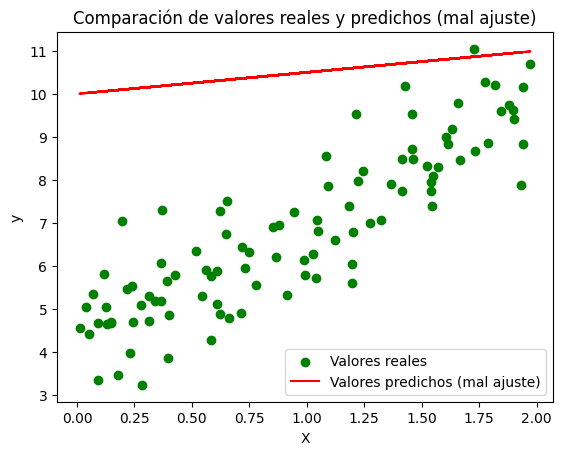

In [8]:
# Generar predicciones incorrectas (forzando un mal ajuste)
y_predMal = 10 + 0.5 * X  # Valores predichos que no se ajustan bien a los datos reales

mse =mean_squared_error(y, y_predMal)
rmse = root_mean_squared_error(y, y_predMal)

# Valores mínimos y máximos de y
y_min = np.min(y)
y_max = np.max(y)

print("Y min:", y_min)
print("Y max:", y_max)
print("MSE:", mse)
print("RMSE:", rmse)

# Gráfico comparativo
plt.scatter(X, y, color='green', label='Valores reales')
plt.plot(X, y_predMal, color='red', label='Valores predichos (mal ajuste)')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.title('Comparación de valores reales y predichos (mal ajuste)')
plt.show()

### SGDRegressor (descenso del gradiente estocástico)
El descenso de gradiente estocástico (SGD) es un algoritmo de **optimización** utilizado para **ajustar los parámetros de un modelo de aprendizaje automático**, como los coeficientes de una regresión lineal, minimizando una función de pérdida (por ejemplo, el error cuadrático medio).

Al utilizar esta clase, el modelo asume que quieres realizar una regresión lineal por defecto. Esto se debe a que SGDRegressor minimiza el error cuadrático medio (MSE) de manera predeterminada, lo cual es el criterio estándar para la regresión lineal.

El modelo se ejecuta durante un máximo de 1.000 repeticiones (max_iter) o hasta que la pérdida se reduzca en menos de 1e-5 (tol) durante 100 repeticiones (n_iter_no_change). No utiliza ninguna regularización (penalty=None) y la tasa de aprendizaje inicial es 0.01

In [9]:
sgd_reg = SGDRegressor(max_iter=1000, tol=1e-5, n_iter_no_change=100, penalty=None, eta0=0.01,  random_state=42)
sgd_reg.fit(X, y.flatten())  # y.flatten() porque fit() espera un vector 1D

SGDRegressor(n_iter_no_change=100, penalty=None, random_state=42, tol=1e-05)

Vamos a obtener los parametros, el intercepto y los coeficientes,  del modelo de regresión lineal entrenado utilizando el algortimo de descenso de gradiente estostático(SGD)

In [10]:
sgd_reg.intercept_, sgd_reg.coef_

(array([4.21278812]), array([2.77270267]))

In [11]:
y_pred = sgd_reg.predict(X) #Utiliza el modelo de regresión lineal  entrenado (sgd_reg) para predecir los valores de y, basados en los datos de entreda X
rmse = root_mean_squared_error(y, y_pred) #Se aplica la formula del error cuadratico medio (RMSE) para calcular la raiz del error cuadratico medio entre los valores reales de y y los valores predichos de y
y_min = np.min(y) #Obtenemos el valor minimo de la variable objetivo 'y' en el conjunto de datos
y_max = np.max(y) #Obtenemos el valor maximo de la variable objetivo 'y' en el conjunto de datos
print("Y min:", y_min)
print("Y max:", y_max)
print("RMSE:", rmse)

Y min: 3.2380621152873488
Y max: 11.044395066398318
RMSE: 0.8981018481577449


#### Interpretación de resultados de Linear Regression SGDRegressor:
* `Comparación con el rango de y`:
    * El RMSE de 0.89 es relativamente pequeño en comparación con el rango de y (3.24 a 11.04). Esto sugiere que el modelo está haciendo un buen trabajo al predecir los valores de y, ya que el error promedio de las predicciones es pequeño en relación con el rango total de los valores.
* `Evaluación general`:
    * Un RMSE de 0.90 en un rango de valores de y que va de 3.24 a 11.04 indica que el modelo tiene una precisión razonablemente buena. Es más, prácticamente da el mismo resultado de el modelo de regresi
    on lineal


### LinearSVR

Implementación del algoritmo de Máquinas de Vectores de Soporte ( SVM) para regresión lineal. A diferencia de SVR (Support Vector Regression), que puede utilizar diferentes tipos de núcleos (kernels) para manejar relaciones no lineales, LinearSVR está diseñado específicamente para problemas de regresión lineal y utiliza un núcleo lineal.

El objetivo es minimizar el error de predicción mientras se maximiza el margen, es decir, la distancia entre los puntos de datos más cercanos y la línea de regresión.

Función de Pérdida Epsilon-Insensible: utiliza epsilon-insensible, lo que significa que no penaliza los errores que están dentro de un margen epsilon alrededor de la línea de regresión. Esto permite que el modelo sea más robusto a los ruidos en los dato

In [12]:
svr_reg = LinearSVR(epsilon=0.5, random_state=42) #Se crea un modelo de regresión de vectores de soporte lineal (LinearSVR) con un valor de epsilon de 0.5 y una semilla de aleatoriedad de 42
svr_reg.fit(X, y.flatten())

LinearSVR(epsilon=0.5, random_state=42)

In [13]:
svr_reg.intercept_, svr_reg.coef_ #Se obtiene el valor del intercepto y los coeficientes del modelo de regresión de vectores de soporte lineal (svr_reg)

(array([4.02740704]), array([2.86270582]))

In [14]:
y_pred = svr_reg.predict(X)
rmse = root_mean_squared_error(y, y_pred)
y_min = np.min(y)
y_max = np.max(y)
print("Y min:", y_min)
print("Y max:", y_max)
print("RMSE:", rmse)

Y min: 3.2380621152873488
Y max: 11.044395066398318
RMSE: 0.9053802048583451


#### Interpretación de resultados de Linear Regression LinearSVR:
* `Comparación con el rango de y`:
    * El RMSE de 0.91 es relativamente pequeño en comparación con el rango de y (3.24 a 11.04). Esto sugiere que el modelo está haciendo un buen trabajo al predecir los valores de y, ya que el error promedio de las predicciones es pequeño en relación con el rango total de los valores.
* `Evaluación general`:
    * Un RMSE de 0.91 en un rango de valores de y que va de 3.24 a 11.04 indica que el modelo tiene una precisión razonablemente buena. Aunque no es perfecto, el error es relativamente pequeño en comparación con el rango de los datos, lo que sugiere que el modelo es capaz de capturar la relación lineal subyacente en los datos.


#### Interpretación Final de Resultados:
* LinearRegression tiene el RMSE más bajo (0.8981005311027566), seguido muy de cerca por SGDRegressor (0.8981018481577449). Ambos modelos tienen un rendimiento muy similar y significativamente mejor que LinearSVR.
* LinearSVR tiene el RMSE más alto (0.9053802048583451), lo que indica que, de los tres modelos, es el que menos se ajusta a los datos.

## EJEMPLO 2: REGRESIÓN POLINOMIAL

Primero, generamos datos no lineales, basados en una ecuación de segundo grado simple (que es una ecuación con la forma **y = ax2 + bx + c**) y algo de ruido

In [15]:
np.random.seed(42)
m = 1000
X_train = 6 * np.random.rand(m, 1) - 3
y_train = 0.5 * X_train ** 2 + X_train + 2 + np.random.randn(m, 1)

m=100
X_test=  6 * np.random.rand(m, 1) - 3
y_test = 0.5 * X_test ** 2 + X_test + 2 + np.random.randn(m, 1)


Vamos a representar los datos

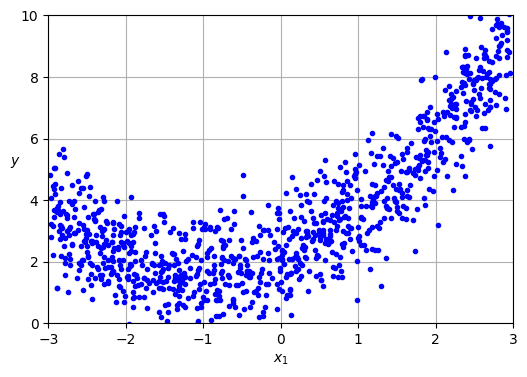

In [16]:
plt.figure(figsize=(6, 4))
plt.plot(X_train, y_train, "b.")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([-3, 3, 0, 10])
plt.grid()
plt.show()

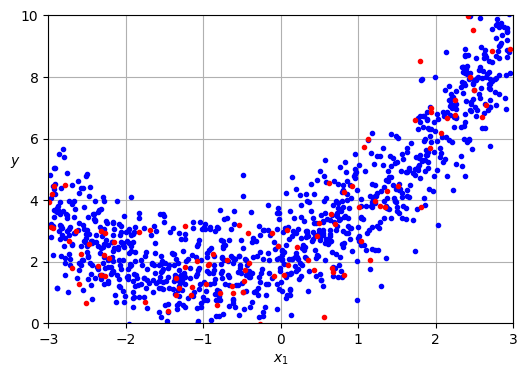

In [17]:
plt.figure(figsize=(6, 4))
plt.plot(X_train, y_train, "b.")
plt.plot(X_test, y_test, "r.")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([-3, 3, 0, 10])
plt.grid()
plt.show()

Está claro que una línea recta nunca se ajustará a estos datos de forma adecuada. 

Vamos a utilizar la clase PolynomialFeatures de Scikit-Learn para transformar nuestros datos de entrenamiento, añadiendo el cuadrado (polinomio de segundo grado) de cada característica en el conjunto de entrenamiento como una característica nueva (en este caso, solo hay una característica). 

In [18]:
poly_features = PolynomialFeatures(degree=2, include_bias=False) #Se crea un objeto de PolynomialFeatures con un grado de 2 y sin incluir el sesgo que ayuda a generar nuevas características polinómicas hasta segundo grado a partir de las características existentes
X_poly = poly_features.fit_transform(X_train) #metodo transform() para generar las nuevas características polinómicas a partir de las características existentes

Este es el valor transformado de la primera característica en el conjunto de datos X_poly, que incluye las características polinómicas generadas a partir de X[0].

In [19]:
print(X_train[0])
print(X_poly[0])

[-0.75275929]
[-0.75275929  0.56664654]


PolynomialFeatures ha transformado la característica original `X[0]` en un conjunto de características polinómicas [`X_poly[0]`], que incluye la característica original y su cuadrado. Esta transformación puede ayudar a capturar relaciones no lineales en los datos cuando se utiliza en modelos de regresión.

Ya podemos ajustar un modelo LinearRegression a este conjunto de datos ampliado:

In [20]:
lin_reg = LinearRegression()
lin_reg.fit(X_poly, y_train)
lin_reg.intercept_, lin_reg.coef_

(array([2.13655913]), array([[0.97357761, 0.48724005]]))

* Intercepto: El intercepto es el valor de y cuando todas las características en X_poly son 0 (la c en la ecuación de segundo grado).
* Coeficientes: Los coeficientes representan la relación entre cada característica en X_poly y la variable objetivo y. 
    * El primer coeficiente corresponde a la característica original (la b).
    * El segundo coeficiente corresponde al cuadrado de la característica original (la a).

Mejor todo en una pipeline, es decir, encadenar múltiples pasos de procesamiento y modelado en una secuencia ordenada. 

In [21]:
polinomial_modelo = make_pipeline(PolynomialFeatures(degree=2, include_bias=False),StandardScaler(), LinearRegression()) #Se crea un modelo de regresión polinómica de segundo grado utilizando make_pipeline() que combina PolynomialFeatures y LinearRegression
polinomial_modelo.fit(X_train, y_train) #Se entrena el modelo de regresión polinómica de segundo grado con las características originales X y la variable objetivo y
polinomial_modelo.named_steps['linearregression'].coef_, polinomial_modelo.named_steps['linearregression'].intercept_  #Se obtiene el valor del intercepto y los coeficientes del modelo de regresión polinómica de segundo grado

(array([[1.70565689, 1.31244185]]), array([3.57680406]))

No está mal: el modelo estima $\hat{y} = 1.71x_1^2 + 1.31x_1 + 3.57$ 

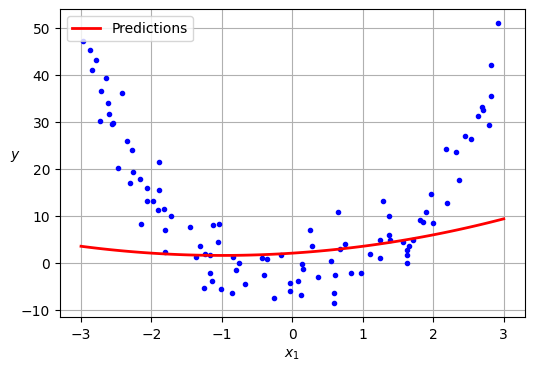

In [ ]:
X_new = np.linspace(-3, 3, 100).reshape(100, 1)
y_new = polinomial_modelo.predict(X_new)

plt.figure(figsize=(6, 4))
plt.plot(X, y, "b.")
plt.plot(X_new, y_new, "r-", linewidth=2, label="Predictions")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.legend(loc="upper left")
plt.grid()
plt.show()

In [23]:
y_pred = polinomial_modelo.predict(X_train)
rmse = root_mean_squared_error(y_train, y_pred)
y_min = np.min(y)
y_max = np.max(y)
print("Y min:", y_min)
print("Y max:", y_max)
print("RMSE:", rmse)

Y min: 3.2380621152873488
Y max: 11.044395066398318
RMSE: 0.9868068442612644


#### Interpretación de resultados de PolynomialFeatures:
* Basado en el RMSE de 0.88 y el rango de y (0.06 a 9.97), tu modelo polinómico parece tener un buen desempeño. El error promedio de las predicciones es pequeño en relación con el rango total de los valores de `y`, lo que indica que el modelo es preciso y fiable para las predicciones en este contexto.


Un punto clave en la regresión polinomica es determinar el valor del hiperparamatro degree:
- Con un degree bajo puede que nuestro modelo subajuste
- Con un degree alto puedo que nuestro modelo sobreajuste, además los calculos serán más costosos

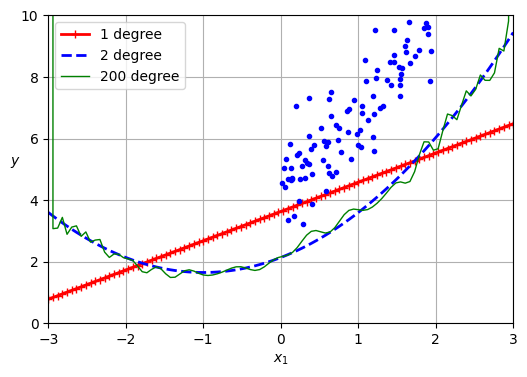

In [24]:
plt.figure(figsize=(6, 4))

for style, width, degree in (("r-+", 2, 1), ("b--", 2, 2), ("g-", 1, 200)):
    polybig_features = PolynomialFeatures(degree=degree, include_bias=False)
    std_scaler = StandardScaler()
    lin_reg = LinearRegression()
    polynomial_regression = make_pipeline(polybig_features, std_scaler, lin_reg)
    polynomial_regression.fit(X_train, y_train)
    y_newbig = polynomial_regression.predict(X_new)
    label = "{} degree".format(degree)
    plt.plot(X_new, y_newbig, style, label=label, linewidth=width)

plt.plot(X, y, "b.", linewidth=3)
plt.legend(loc="upper left")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([-3, 3, 0, 10])
plt.grid()
plt.show()

### Decidir cual es el mejor degree

Para decidir cual es el mejor degree para nuestro modelo lo mejor es representar como evoluciona el error gráficamente con distintos k

Grado: 1, error entrenamiento:1.6415065922623147 , error test: 1.8105760750290032
Grado: 2, error entrenamiento:0.9868068442612644 , error test: 1.0640919833692233
Grado: 3, error entrenamiento:0.9863350380438782 , error test: 1.0627281128693744


Grado: 4, error entrenamiento:0.9846492805286489 , error test: 1.0690932452252666
Grado: 5, error entrenamiento:0.9844595293237265 , error test: 1.0713947209793044


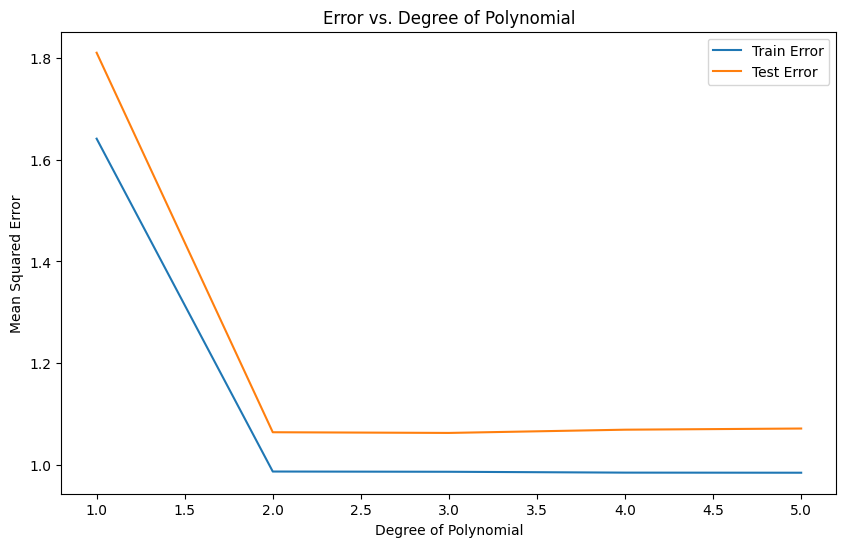

In [25]:
degrees = [1, 2, 3, 4, 5]
train_errors = []
test_errors = []

for degree in degrees:
    model=make_pipeline(PolynomialFeatures(degree=degree, include_bias=False), StandardScaler(), LinearRegression())
    model.fit(X_train, y_train)
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    train_error=root_mean_squared_error(y_train, y_train_pred)
    test_error=root_mean_squared_error(y_test, y_test_pred)
    train_errors.append(train_error)
    test_errors.append(test_error)
    print("Grado: {}, error entrenamiento:{} , error test: {}".format(degree, train_error,test_error))
plt.figure(figsize=(10, 6))
plt.plot(degrees, train_errors, label='Train Error')
plt.plot(degrees, test_errors, label='Test Error')
plt.xlabel('Degree of Polynomial')
plt.ylabel('Mean Squared Error')
plt.title('Error vs. Degree of Polynomial')
plt.legend()
plt.show()

De la gráfica podemos interpretar que el mejor degree para este caso es 2, a partir de 2 puede bajar un poco el error de entrenamiento, pero aumenta el de validación (empieza a sobreajustar)

### Curvas de aprendizaje

La curvas de aprendizaje son gráficos del error de entrenamiento y el error de validación según aumenta el tamaño del conjunto de entrenamiento, que nos permiten ver que está pasando con nuestro modelo: subajuste, sobreajuste...

Con Scikit-Learn es muy sencillo de hacer con la función learning_curve(): entrena y evalúa el modelo utilizando la validación cruzada.

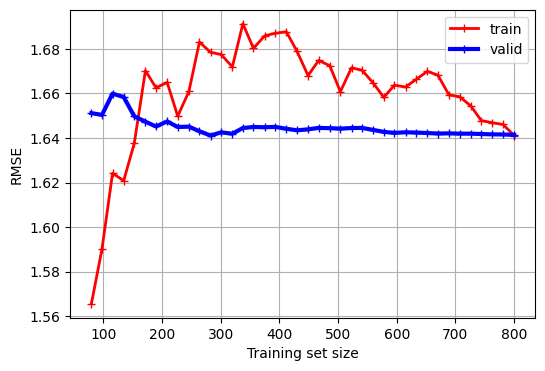

In [26]:
# train_sizes=np.linspace(0.01, 1.0, 40) - Divide el conjunto de entrenamiento en 40 trocitos equidistantes
aux = np.linspace(0.1, 1.0, 40)  # 40 puntos del 10% al 100% del total (en un principio teniamos 1000 datos 
#pero la validación cruzaada lo divide en 5 partes, por lo que tenemos 200 datos para la validación y 800 para el entrenamiento)

train_sizes, train_scores, valid_scores = learning_curve(
    LinearRegression(), X_train, y_train, train_sizes=aux, cv=5,
    scoring="neg_root_mean_squared_error") 
# La función devuelve los tamaños del conjunto de entrenamiento en los que ha evaluado el modelo y las puntuaciones de entrenamiento y validación que ha medido para cada tamaño y para cada iteración de la validación cruzada
train_errors = -train_scores.mean(axis=1)
valid_errors = -valid_scores.mean(axis=1)

plt.figure(figsize=(6, 4)) 
plt.plot(train_sizes, train_errors, "r-+", linewidth=2, label="train")
plt.plot(train_sizes, valid_errors, "b-+", linewidth=3, label="valid")

plt.xlabel("Training set size")
plt.ylabel("RMSE")
plt.grid()
plt.legend(loc="upper right")
#plt.axis([0, 1000, 0, 2.5])

plt.show()

Estas curvas de aprendizaje son típicas de un modelo que está subajustando, el error en train es mayor que en test

Ahora vamos a fijarnos en las curvas de aprendizaje de un modelo polinomial de décimo grado con los mismos datos.

In [27]:
polynomial_regression = make_pipeline( PolynomialFeatures(degree=10, include_bias=False),LinearRegression())
train_sizes, train_scores, valid_scores = learning_curve(
    polynomial_regression, X_train, y_train, train_sizes=np.linspace(0.1, 1.0, 40), cv=5,
    scoring="neg_root_mean_squared_error")
train_errors = -train_scores.mean(axis=1)
valid_errors = -valid_scores.mean(axis=1)

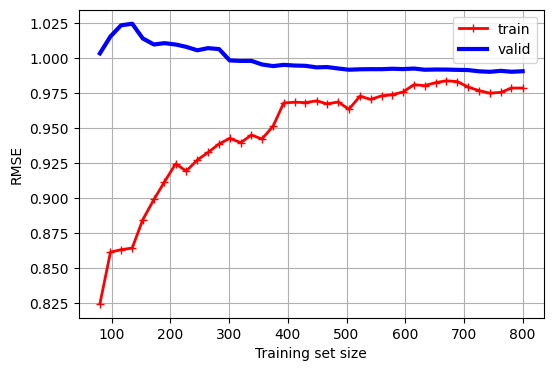

In [28]:
plt.figure(figsize=(6, 4))
plt.plot(train_sizes, train_errors, "r-+", linewidth=2, label="train")
plt.plot(train_sizes, valid_errors, "b-", linewidth=3, label="valid")
plt.legend(loc="upper right")
plt.xlabel("Training set size")
plt.ylabel("RMSE")
plt.grid()
#plt.axis([0, 80, 0, 2.5])
plt.show()

Hay un espacio entre las curvas. Eso significa que el modelo tiene un rendimiento bastante mejor en los datos de entrenamiento que en los de validación, lo cual es una marca distintiva de un modelo que sobreajusta.

Vamos a ver ahora que pasa con grado 2

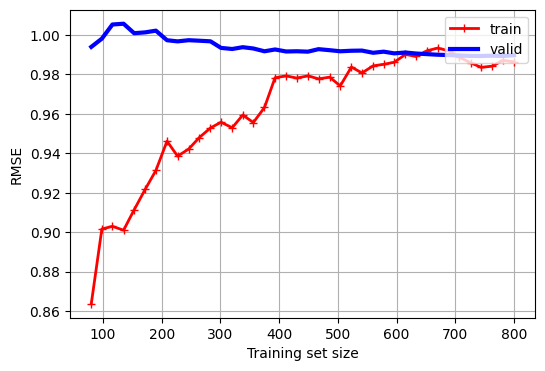

In [29]:
polynomial_regression = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression())
train_sizes, train_scores, valid_scores = learning_curve(
    polynomial_regression, X_train, y_train, train_sizes=np.linspace(0.1, 1.0, 40), cv=5,
    scoring="neg_root_mean_squared_error")
train_errors = -train_scores.mean(axis=1)
valid_errors = -valid_scores.mean(axis=1)

plt.figure(figsize=(6, 4))
plt.plot(train_sizes, train_errors, "r-+", linewidth=2, label="train")
plt.plot(train_sizes, valid_errors, "b-", linewidth=3, label="valid")
plt.legend(loc="upper right")
plt.xlabel("Training set size")
plt.ylabel("RMSE")
plt.grid()
plt.show()

En la gráfica podemos ver que grado 2 es más adecuado la diferencia entre entrenamiento y validación es mínima (la de entrenamiento es menor, lo cual es lo lógico) pero el error es más bajo que sin usar el modelo polinomial.

## EJEMPLO 3: REGULARIZACIÓN

Una buena forma de reducir el sobreajuste es regularizar el modelo 

Vamos a crear unos datos de prueba

In [30]:
np.random.seed(42)
m = 100
X = 6 * np.random.rand(m, 1) - 3 
y = (0.1 * X**5 + 0.5 * X**4 - X**3 + X**2 + 2 * X + np.random.randn(m, 1) * 5) #Polinomio de Quinto Grado: La variable y se genera utilizando un polinomio de quinto grado con coeficientes específicos y un término de error aleatorio
X_new = np.linspace(-3, 3, 100).reshape(100, 1) #Se crea un conjunto de datos de prueba X_new que contiene 100 valores equidistantes entre -3 y 3 convierte el vector en una matriz de 100x1
                                                #Esto es necesario para que los datos tengan la forma correcta para ser utilizados en modelos de regresión.

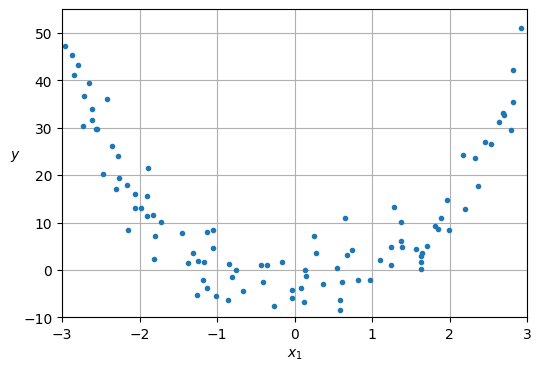

In [31]:
plt.figure(figsize=(6, 4))
plt.plot(X, y, ".")
plt.xlabel("$x_1$")
plt.ylabel("$y$  ", rotation=0)
plt.axis([-3, 3, -10, 55])
plt.grid()
plt.show()

In [32]:
poly_features = PolynomialFeatures(degree=30, include_bias=False) #Se crea un objeto de PolynomialFeatures con un grado de 30 y sin incluir el sesgo que ayuda a generar nuevas características polinómicas hasta el grado 30 a partir de las características existentes
lin_reg = LinearRegression()
pipeline_lin = make_pipeline(poly_features, lin_reg) #Se crea un modelo de regresión lineal utilizando make_pipeline() que combina PolynomialFeatures y LinearRegression
pipeline_lin.fit(X, y) #Se entrena el modelo de regresión lineal con las características polinómicas generadas y la variable objetivo y

Pipeline(steps=[('polynomialfeatures',
                 PolynomialFeatures(degree=30, include_bias=False)),
                ('linearregression', LinearRegression())])

In [33]:
y_pred_lin = pipeline_lin.predict(X) #Utiliza el modelo de regresión lineal entrenado (pipeline_lin) para predecir los valores de y
rmse_lin =root_mean_squared_error(y, y_pred_lin) 
y_min = np.min(y)
y_max = np.max(y)
print("Y min:", y_min)
print("Y max:", y_max)
print("RMSE:", rmse_lin)

Y min: -8.542299598188182
Y max: 51.04690761850233
RMSE: 5.923888919433624


#### Interpretación de resultados de PolynomialFeatures Regularizado:
* basado en el RMSE de 5.85 y el rango de y (-8.54 a 51.05), tu modelo de regresión lineal parece tener un desempeño deficiente. El error promedio de las predicciones es grande en relación con el rango total de los valores de y, lo que indica que el modelo no es preciso y fiable para las predicciones en este contexto.
* Posibles razones:
    * **Modelo Inadecuado**:La relación entre las características y la variable objetivo podría no ser lineal. Considera utilizar un modelo más complejo, como una regresión polinómica o un modelo basado en árboles.
    * **Características Insuficientes**:Es posible que las características actuales no capturen toda la información necesaria para predecir y. Intenta agregar más características o transformar las existentes.
    * **Ruido en los Datos**:Si los datos tienen mucho ruido, puede ser difícil para el modelo capturar la relación subyacente. Considera técnicas de preprocesamiento para reducir el ruido.


### REGRESIÓN DE RIDGE (L2)

El hiperparámetro α controla cuánto queremos regularizar el modelo. Si α=0, entonces no hay regularización. Si α es muy grande, entonces todos los pesos acaban muy cerca de cero y el resultado es una línea plana que cruza la media de los datos.

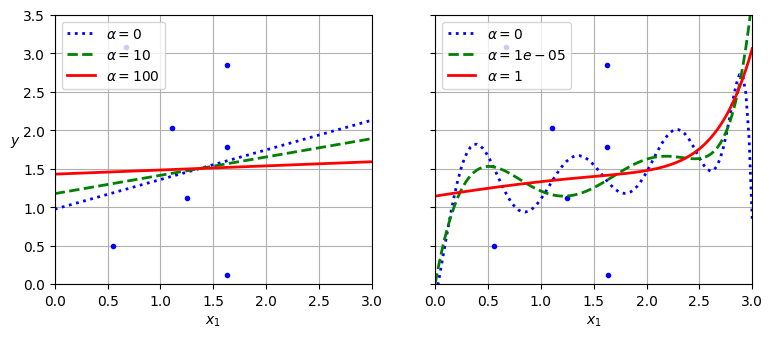

In [34]:
np.random.seed(42)
m = 20
X_dib = 3 * np.random.rand(m, 1)
y_dib = 1 + 0.5 * X_dib + np.random.randn(m, 1) / 1.5
X_dib_new = np.linspace(0, 3, 100).reshape(100, 1)

def plot_model(model_class, polynomial, alphas, **model_kwargs):
    plt.plot(X, y, "b.", linewidth=3)
    for alpha, style in zip(alphas, ("b:", "g--", "r-")):
        if alpha > 0:
            model = model_class(alpha, **model_kwargs)
        else:
            model = LinearRegression()
        if polynomial:
            model = make_pipeline(
                PolynomialFeatures(degree=10, include_bias=False),
                StandardScaler(),
                model)
        model.fit(X_dib, y_dib)
        y_new_regul = model.predict(X_dib_new)
        plt.plot(X_dib_new, y_new_regul, style, linewidth=2,  label=fr"$\alpha = {alpha}$")
    plt.legend(loc="upper left")
    plt.xlabel("$x_1$")
    plt.axis([0, 3, 0, 3.5])
    plt.grid()

plt.figure(figsize=(9, 3.5))
plt.subplot(121)
plot_model(Ridge, polynomial=False, alphas=(0, 10, 100), random_state=42)
plt.ylabel("$y$  ", rotation=0)
plt.subplot(122)
plot_model(Ridge, polynomial=True, alphas=(0, 10**-5, 1), random_state=42)
plt.gca().axes.yaxis.set_ticklabels([])
plt.show()

Vamos a aplicar la regresión de Ridge a nuestros datos

In [35]:
poly_features = PolynomialFeatures(degree=30, include_bias=False)
ridge_reg = Ridge(alpha=1.,random_state=42)
pipeline_ridge = make_pipeline(poly_features, ridge_reg)
pipeline_ridge.fit(X, y)

Pipeline(steps=[('polynomialfeatures',
                 PolynomialFeatures(degree=30, include_bias=False)),
                ('ridge', Ridge(random_state=42))])

In [36]:
y_pred_ridge = pipeline_ridge.predict(X)
rmse_ridge = root_mean_squared_error(y, y_pred_ridge)
y_min = np.min(y)
y_max = np.max(y)
print("Y min:", y_min)
print("Y max:", y_max)
print("RMSE:", rmse_ridge)

Y min: -8.542299598188182
Y max: 51.04690761850233
RMSE: 4.062002115289817


RMSE regresion lineal: 5.923888919433624
RMSE ridge: 4.062002115289817


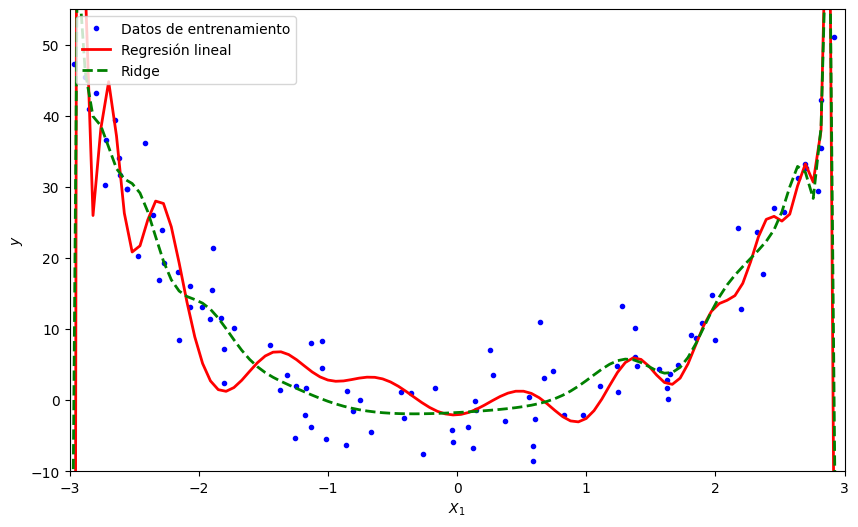

In [37]:
print(f"RMSE regresion lineal: {rmse_lin}")
print(f"RMSE ridge: {rmse_ridge}")

y_pred_lin1 = pipeline_lin.predict(X_new)
y_pred_ridge1 = pipeline_ridge.predict(X_new)

plt.figure(figsize=(10, 6))
plt.plot(X, y, "b.", label="Datos de entrenamiento")
plt.plot(X_new, y_pred_lin1, "r-", linewidth=2, label="Regresión lineal")
plt.plot(X_new, y_pred_ridge1, "g--", linewidth=2, label="Ridge")
plt.xlabel("$X_1$")
plt.ylabel("$y$")
plt.legend(loc="upper left")
plt.axis([-3, 3, -10, 55])
plt.show()

### REGRESIÓN DE LASSO (L1)

La regresión Lasso es otra versión regularizada de la regresión lineal. 

El hiperparámetro α también controla cuánto queremos regularizar el modelo. Si α=0, entonces no hay regularización. Si α es muy grande, entonces todos los pesos acaban muy cerca de cero y el resultado es una línea plana que cruza la media de los datos.

Una característica importante de la regresión Lasso es que tiende a eliminar los pesos de las características menos importantes (es decir, los pone a cero).

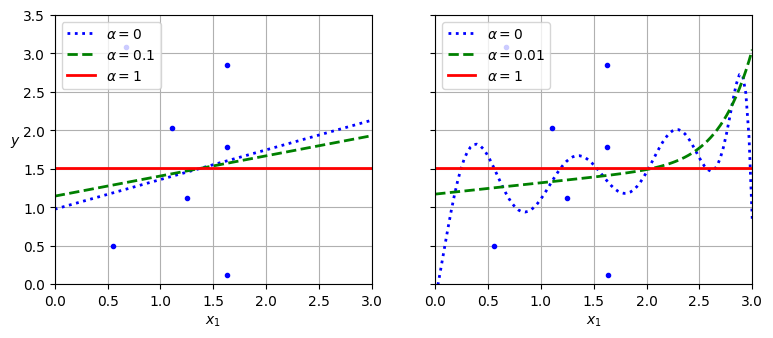

In [38]:
plt.figure(figsize=(9, 3.5))
plt.subplot(121)
plot_model(Lasso, polynomial=False, alphas=(0, 0.1, 1), random_state=42)
plt.ylabel("$y$  ", rotation=0)
plt.subplot(122)
plot_model(Lasso, polynomial=True, alphas=(0, 1e-2, 1), random_state=42)
plt.gca().axes.yaxis.set_ticklabels([])
plt.show()

Vamos a aplicar la regresión de Lasso a nuestros datos

In [39]:
poly_features = PolynomialFeatures(degree=30, include_bias=False)
lasso_reg = Lasso(alpha=1.,random_state=42)
pipeline_lasso = make_pipeline(poly_features, lasso_reg)
pipeline_lasso.fit(X, y)

/opt/anaconda3/envs/sapa/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.037e+03, tolerance: 2.194e+00
  model = cd_fast.enet_coordinate_descent(


Pipeline(steps=[('polynomialfeatures',
                 PolynomialFeatures(degree=30, include_bias=False)),
                ('lasso', Lasso(random_state=42))])

In [40]:
y_pred_lasso = pipeline_lasso.predict(X)
rmse_lasso = root_mean_squared_error(y, y_pred_lasso)
y_min = np.min(y)
y_max = np.max(y)
print("Y min:", y_min)
print("Y max:", y_max)
print("RMSE:", rmse_lasso)

Y min: -8.542299598188182
Y max: 51.04690761850233
RMSE: 4.375377943416326


RMSE regresion lineal: 5.923888919433624
RMSE ridge: 4.375377943416326


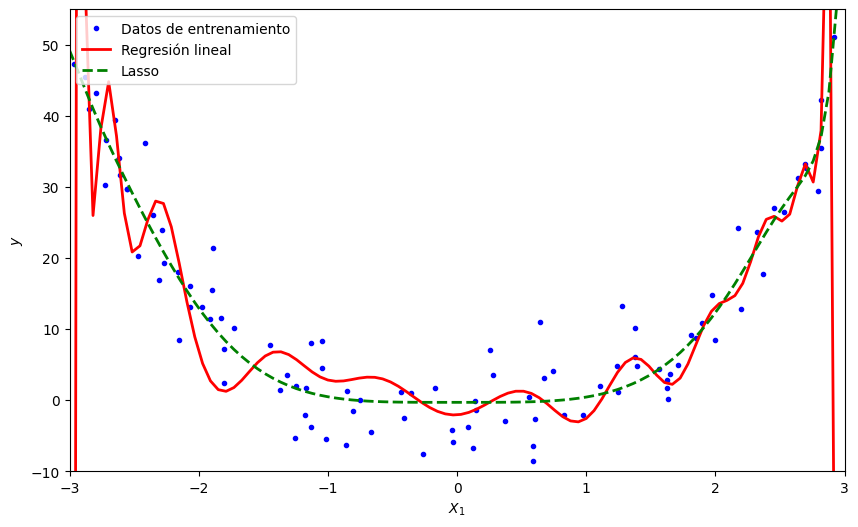

In [41]:
print(f"RMSE regresion lineal: {rmse_lin}")
print(f"RMSE ridge: {rmse_lasso}")

y_pred_lin1 = pipeline_lin.predict(X_new)
y_pred_lasso1 = pipeline_lasso.predict(X_new)

plt.figure(figsize=(10, 6))
plt.plot(X, y, "b.", label="Datos de entrenamiento")
plt.plot(X_new, y_pred_lin1, "r-", linewidth=2, label="Regresión lineal")
plt.plot(X_new, y_pred_lasso1, "g--", linewidth=2, label="Lasso")
plt.xlabel("$X_1$")
plt.ylabel("$y$")
plt.legend(loc="upper left")
plt.axis([-3, 3, -10, 55])
plt.show()

### REGRESIÓN DE RED ELÁSTIC (ELASTIC NET)

La regresión de red elástica es un punto medio entre la regresión de Ridge y la regresión Lasso. Podemos controlar la relación de mezcla con el hiperparametro l1_ratio. Cuando l1_ratio= 0, la red elástica es equivalente a la regresión de Ridge y, cuando r = 1, es equivalente a la regresión Lasso.

Vamos a aplicar Elastic net a nuestros datos

In [42]:
poly_features = PolynomialFeatures(degree=30, include_bias=False)
net_reg = ElasticNet(alpha=0.1, l1_ratio=0.5)
pipeline_net = make_pipeline(poly_features, net_reg)
pipeline_net.fit(X, y)

/opt/anaconda3/envs/sapa/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.463e+02, tolerance: 2.194e+00
  model = cd_fast.enet_coordinate_descent(


Pipeline(steps=[('polynomialfeatures',
                 PolynomialFeatures(degree=30, include_bias=False)),
                ('elasticnet', ElasticNet(alpha=0.1))])

In [43]:
y_pred_net = pipeline_net.predict(X)
rmse_net = root_mean_squared_error(y, y_pred_net)
y_min = np.min(y)
y_max = np.max(y)
print("Y min:", y_min)
print("Y max:", y_max)
print("RMSE:", rmse_net)

Y min: -8.542299598188182
Y max: 51.04690761850233
RMSE: 4.299682525205398


RMSE regresion lineal: 5.923888919433624
RMSE elastic net: 4.299682525205398


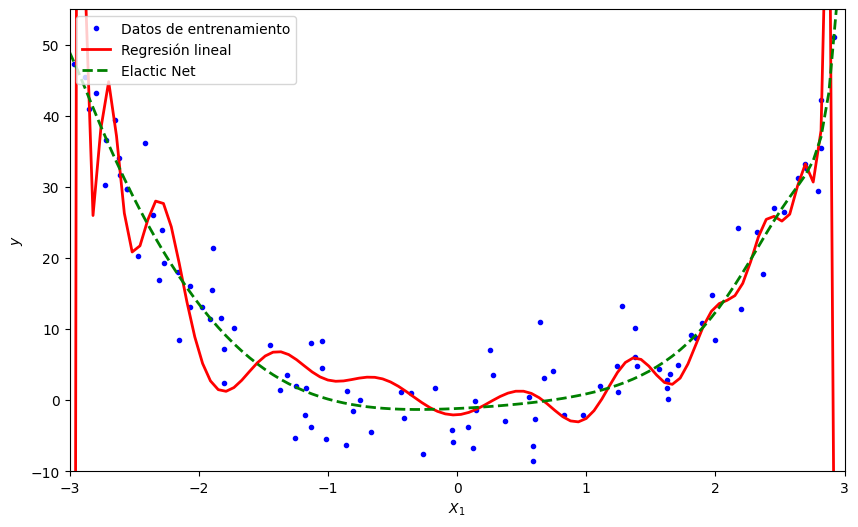

In [44]:
print(f"RMSE regresion lineal: {rmse_lin}")
print(f"RMSE elastic net: {rmse_net}")

y_pred_lin1 = pipeline_lin.predict(X_new)
y_pred_net1 = pipeline_net.predict(X_new)

plt.figure(figsize=(10, 6))
plt.plot(X, y, "b.", label="Datos de entrenamiento")
plt.plot(X_new, y_pred_lin1, "r-", linewidth=2, label="Regresión lineal")
plt.plot(X_new, y_pred_net1, "g--", linewidth=2, label="Elactic Net")
plt.xlabel("$X_1$")
plt.ylabel("$y$")
plt.legend(loc="upper left")
plt.axis([-3, 3, -10, 55])
plt.show()

## EJEMPLO 4: ÁRBOLES DE DECISIÓN

Los árboles de decisión asumen muy pocas cosas sobre los datos de entrenamiento. Si se deja sin restricciones, la estructura del árbol se adaptará a los datos de entrenamiento, ajustándolos mucho, de hecho, sobre ajustándolos muy probablemente.

Para evitar el sobreajuste hay que configurar correctamente sus hiperparametros:
-	max_depth: restringe la profundidad máxima del árbol. Su valor por defecto es None, es decir sin límites.
-	max_features: restringe el número máximo de características que se evalúan para dividir en cada nodo.
-	max_leaf_nodes: restringe el número máximo de nodos terminales.
-	min_samples_split: restringe el número mínimo de muestras que debe tener un nodo antes de poder dividirse.
-	min_samples_leaf: restringe el número mínimo de muestras que debe tener un nodo terminal para crearse.
-	min_weight_fraction_leaf: igual que min_samples_leaf, pero expresado como una fracción del número total de instancias ponderadas.

Vamos a crear un árbol de regresión con la clase DecisionTreeRegressor de Scikit-Learn, entrenándolo con un conjunto de datos cuadrático con ruido con max_depth=2

Creamos los datos

In [45]:
np.random.seed(42)
X_quad = np.random.rand(200, 1) - 0.5 #Se genera un conjunto de datos X_quad con 200 muestras y 1 característica, con valores aleatorios entre -0.5 y 0.5
y_quad = X_quad**2 + 0.025 * np.random.randn(200, 1) #Se genera la variable objetivo y_quad utilizando la característica X_quad y un término de error aleatorio

In [46]:
tree_reg2 = DecisionTreeRegressor(max_depth=2, random_state=42) #Se crea un modelo de árbol de decisión con una profundidad máxima de 2 y una semilla de aleatoriedad de 42
tree_reg2.fit(X_quad, y_quad)

DecisionTreeRegressor(max_depth=2, random_state=42)

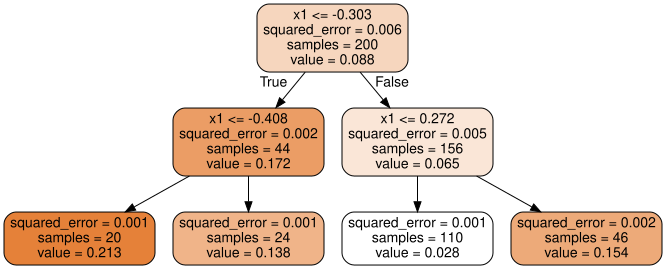

In [ ]:
export_graphviz(
    tree_reg2,
    out_file=str("Resultados/regression_tree2.dot"),
    feature_names=["x1"],
    rounded=True,
    filled=True,
)
Source.from_file("Resultados/regression_tree2.dot")

In [48]:
y_pred_2 = tree_reg2.predict(X_quad)
rmse_2 = root_mean_squared_error(y_quad, y_pred_2)
y_min = np.min(y_quad)
y_max = np.max(y_quad)
print("Y min:", y_min)
print("Y max:", y_max)
print("RMSE:", rmse_2)

Y min: -0.036827231949855314
Y max: 0.28599700903282016
RMSE: 0.03525813914470965


In [49]:
tree_reg3 = DecisionTreeRegressor(max_depth=3, random_state=42)
tree_reg3.fit(X_quad, y_quad)

DecisionTreeRegressor(max_depth=3, random_state=42)

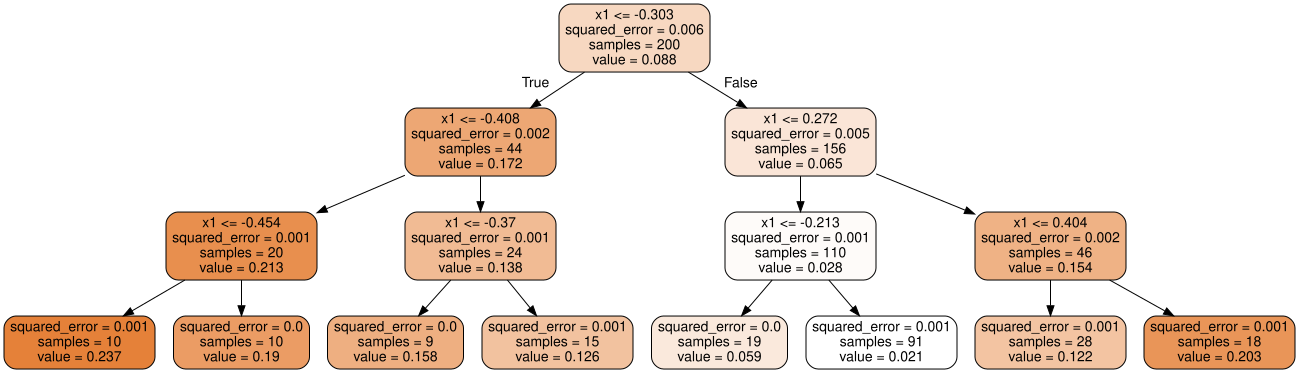

In [ ]:
export_graphviz( 
    tree_reg3,
    out_file=str("Resultados/regression_tree3.dot"),
    feature_names=["x1"],
    rounded=True,
    filled=True,
)
Source.from_file("Resultados/regression_tree3.dot")

In [51]:
y_pred_3 = tree_reg3.predict(X_quad)
rmse_3 = root_mean_squared_error(y_quad, y_pred_3)
y_min = np.min(y_quad)
y_max = np.max(y_quad)
print("Y min:", y_min)
print("Y max:", y_max)
print("RMSE:", rmse_3)

Y min: -0.036827231949855314
Y max: 0.28599700903282016
RMSE: 0.026291731890975657


In [52]:
tree_reg_min_leaf = DecisionTreeRegressor(min_samples_leaf=10, random_state=42)
tree_reg_min_leaf.fit(X_quad, y_quad)

DecisionTreeRegressor(min_samples_leaf=10, random_state=42)

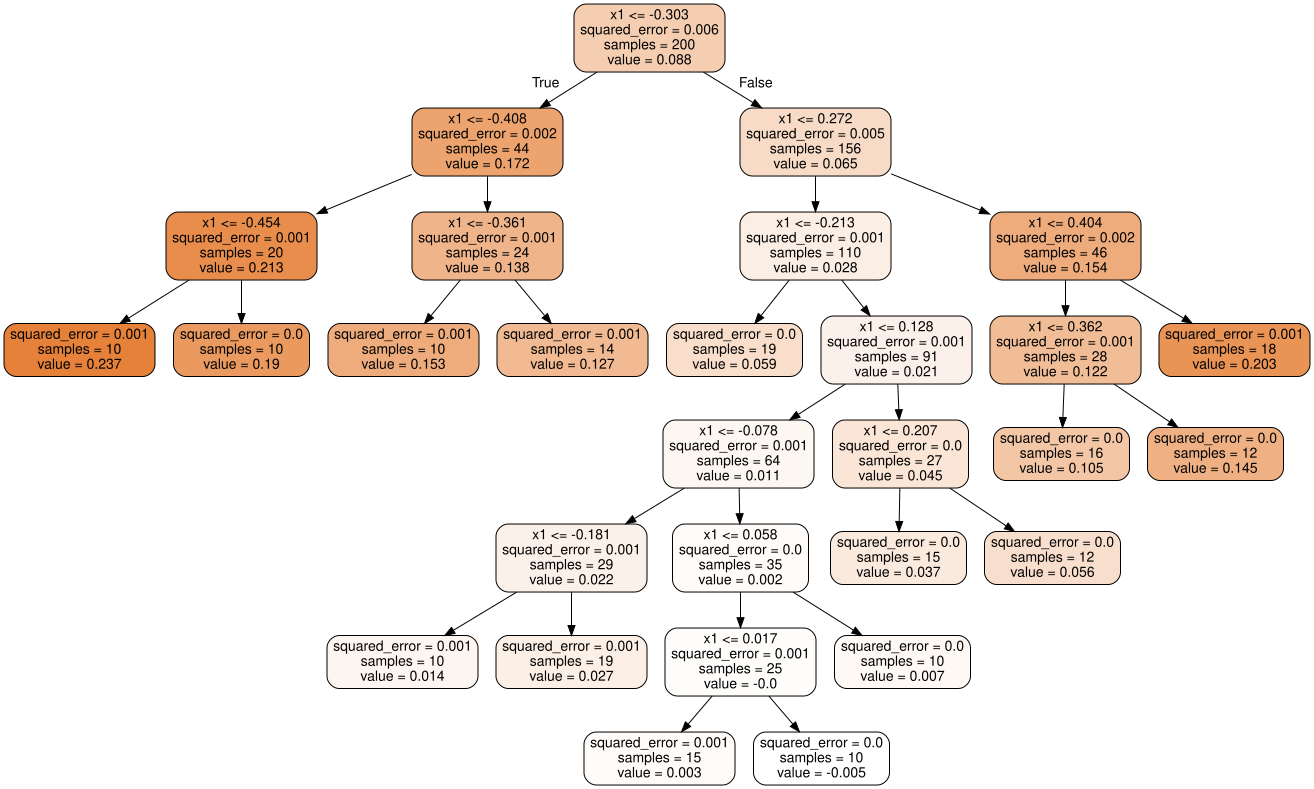

In [ ]:
export_graphviz(
    tree_reg_min_leaf,
    out_file=str("Resultados/regression_tree_min_leaf.dot"),
    feature_names=["x1"],
    rounded=True,
    filled=True,
)
Source.from_file("Resultados/regression_tree_min_leaf.dot")

In [54]:
y_pred_reg_min_leaf = tree_reg_min_leaf.predict(X_quad)
rmse_reg_min_lead = root_mean_squared_error(y_quad, y_pred_reg_min_leaf)
y_min = np.min(y_quad)
y_max = np.max(y_quad)
print("Y min:", y_min)
print("Y max:", y_max)
print("RMSE:", rmse_reg_min_lead)

Y min: -0.036827231949855314
Y max: 0.28599700903282016
RMSE: 0.021930076092116585


El principal problema con los árboles de decisión es que tienen una varianza bastante alta: cambios pequeños en los hiperparámetros o los datos pueden producir modelos muy diferentes. 